# Actividad 5: precio de Airbnb en NYC

Preparación de datos, entrenamiento de tres modelos de regresión (Ridge, XGBoost y MLP en MPS), ajuste con Grid Search y validación cruzada de 10 folds, y registro en MLflow.

La lógica vive en `datos_prep.py` y `train.py`; este cuaderno los usa para explorar, limpiar, entrenar y comparar.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import train
import datos_prep as prep
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

%matplotlib inline
train.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
EVIDENCE = prep.ROOT / "evidencias"
EVIDENCE.mkdir(exist_ok=True)
print(f"Dispositivo para la MLP: {train.DEVICE}")

Dispositivo para la MLP: mps


## 1. Datos originales y verificación de versión

In [2]:
raw = prep.load_raw()
print(f"Archivo: {prep.RAW_PATH.name}")
print(f"SHA-256: {prep.sha256(prep.RAW_PATH)}")
print(f"Filas: {raw.shape[0]:,} | Columnas: {raw.shape[1]}")
raw.head()

Archivo: AB_NYC_2019.csv
SHA-256: e420db40ff10fcb40efc1b5b1648ee0b18a48f4e4537155cecc59fe95d18783a
Filas: 48,895 | Columnas: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.647,-73.972,Private room,149,1,9,2018-10-19,0.210,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.754,-73.984,Entire home/apt,225,1,45,2019-05-21,0.380,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.809,-73.942,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.685,-73.960,Entire home/apt,89,1,270,2019-07-05,4.640,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.799,-73.944,Entire home/apt,80,10,9,2018-11-19,0.100,1,0


In [3]:
raw.dtypes.to_frame("tipo").T

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
tipo,int64,str,int64,str,str,str,float64,float64,str,int64,int64,int64,str,float64,int64,int64


## 2. Calidad inicial

In [4]:
nulls = raw.isna().sum().to_frame("nulos")
nulls["porcentaje"] = nulls["nulos"] / len(raw) * 100
nulls[nulls["nulos"] > 0]

,nulos,porcentaje
name,16,0.033
host_name,21,0.043
last_review,10052,20.558
reviews_per_month,10052,20.558


In [5]:
raw[["price", "minimum_nights", "number_of_reviews", "reviews_per_month", "availability_365"]].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
price,"48,895.000",152.721,240.154,0.000,30.000,106.000,799.000,"10,000.000"
minimum_nights,"48,895.000",7.030,20.511,1.000,1.000,3.000,45.000,"1,250.000"
number_of_reviews,"48,895.000",23.274,44.551,0.000,0.000,5.000,214.000,629.000
reviews_per_month,"38,843.000",1.373,1.680,0.010,0.020,0.720,7.196,58.500
availability_365,"48,895.000",112.781,131.622,0.000,0.000,45.000,365.000,365.000


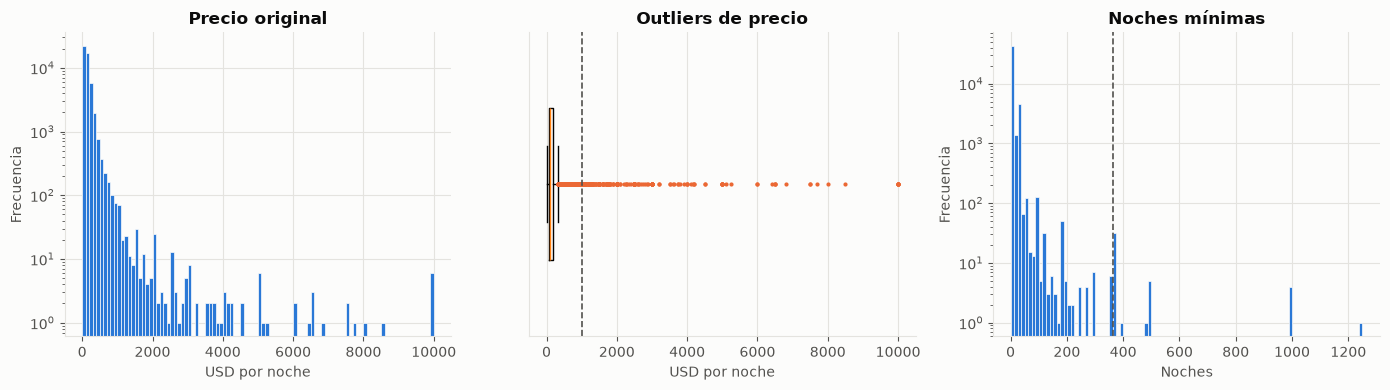

Precio igual a 0: 11 | Precio mayor a 1000: 239
Noches mínimas mayores a 365: 14
Reseñas en 0 y reviews_per_month nulo coinciden: True


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(raw["price"], bins=100, color=train.COLORS["Ridge"], edgecolor=train.SURFACE, linewidth=0.5)
axes[0].set(title="Precio original", xlabel="USD por noche", ylabel="Frecuencia", yscale="log")
axes[1].boxplot(raw["price"], vert=False, widths=0.5, flierprops={"markersize": 3, "markerfacecolor": train.COLORS["XGBoost"], "markeredgecolor": "none"})
axes[1].axvline(prep.PRICE_MAX, color=train.INK_SECONDARY, linestyle="--", linewidth=1.2)
axes[1].set(title="Outliers de precio", xlabel="USD por noche", yticks=[])
axes[2].hist(raw["minimum_nights"], bins=100, color=train.COLORS["Ridge"], edgecolor=train.SURFACE, linewidth=0.5)
axes[2].axvline(prep.MAX_NIGHTS, color=train.INK_SECONDARY, linestyle="--", linewidth=1.2)
axes[2].set(title="Noches mínimas", xlabel="Noches", ylabel="Frecuencia", yscale="log")
fig.tight_layout()
fig.savefig(EVIDENCE / "eda_anomalias.png")
plt.show()
print(f"Precio igual a 0: {(raw['price'] == 0).sum()} | Precio mayor a {prep.PRICE_MAX}: {(raw['price'] > prep.PRICE_MAX).sum()}")
print(f"Noches mínimas mayores a {prep.MAX_NIGHTS}: {(raw['minimum_nights'] > prep.MAX_NIGHTS).sum()}")
print(f"Reseñas en 0 y reviews_per_month nulo coinciden: {((raw['number_of_reviews'] == 0) == raw['reviews_per_month'].isna()).all()}")

In [7]:
key = ["host_id", "name", "room_type", "neighbourhood", "price", "minimum_nights"]
near = raw[raw.duplicated(key, keep=False)].sort_values(key)
print(f"Posibles duplicados por host, nombre y precio: {raw.duplicated(key).sum()}")
near[key + ["latitude", "longitude", "number_of_reviews"]].head(6)

Posibles duplicados por host, nombre y precio: 113


,host_id,name,room_type,neighbourhood,price,minimum_nights,latitude,longitude,number_of_reviews
1066,124357,Spacious Loft 5 min to Union Square,Private room,Williamsburg,90,1,40.718,-73.953,155
2564,124357,Spacious Loft 5 min to Union Square,Private room,Williamsburg,90,1,40.716,-73.958,115
327,417504,Duplex w/ Terrace @ Box House Hotel,Private room,Greenpoint,349,3,40.738,-73.953,8
679,417504,Duplex w/ Terrace @ Box House Hotel,Private room,Greenpoint,349,3,40.737,-73.952,8
652,417504,Loft Suite @ Box House Hotel,Entire home/apt,Greenpoint,199,3,40.738,-73.954,34
674,417504,Loft Suite @ Box House Hotel,Entire home/apt,Greenpoint,199,3,40.737,-73.953,24


Los posibles duplicados por nombre son unidades distintas de un mismo hotel u operador: tienen coordenadas y reseñas propias, por eso se conservan. Solo se eliminan duplicados exactos, por `id` y lógicos (mismo host, coordenadas, tipo y precio).

## 3. Limpieza y estandarización

In [8]:
clean_df, log = prep.clean(raw)
clean_path = prep.save_clean(clean_df)
print(f"Guardado: {clean_path.relative_to(prep.ROOT)}")
print(f"SHA-256 limpio: {prep.sha256(clean_path)}")
log

Guardado: datos/datos_limp/airbnb_nyc_clean.csv
SHA-256 limpio: 5d0e1e21a46edda72d2a4ebb735b094f8b70d0eeab9648918b4bb8ae18d8f88c


,paso,filas_antes,filas_despues,eliminadas
0,Duplicados exactos,48895,48895,0
1,Duplicados por id,48895,48895,0
2,"Duplicados logicos (host, coordenadas, tipo, p...",48895,48894,1
3,Precio fuera de 10 a 1000 USD,48894,48644,250


In [9]:
before = prep.quality_summary(raw)
after = prep.quality_summary(clean_df)
quality = pd.DataFrame({"antes": before, "despues": after})
quality.to_csv(EVIDENCE / "calidad_antes_despues.csv")
quality

,antes,despues
filas,48895,48644
columnas,16,13
nulos_totales,20141,0
duplicados_exactos,0,0
duplicados_id,0,0
duplicados_logicos,1,0
precio_cero,11,0
precio_fuera_rango,250,0
noches_mayor_365,14,0


In [10]:
clean_df.head()

,neighbourhood_group,neighbourhood,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,days_since_last_review,has_reviews,price
0,Brooklyn,Kensington,Private room,40.647,-73.972,1,9,0.210,6,365,262,1,149
1,Manhattan,Midtown,Entire home/apt,40.754,-73.984,1,45,0.380,2,355,48,1,225
2,Manhattan,Harlem,Private room,40.809,-73.942,3,0,0.000,1,365,3024,0,150
3,Brooklyn,Clinton Hill,Entire home/apt,40.685,-73.960,1,270,4.640,1,194,3,1,89
4,Manhattan,East Harlem,Entire home/apt,40.799,-73.944,10,9,0.100,1,0,231,1,80


## 4. Visualizaciones del dataset limpio

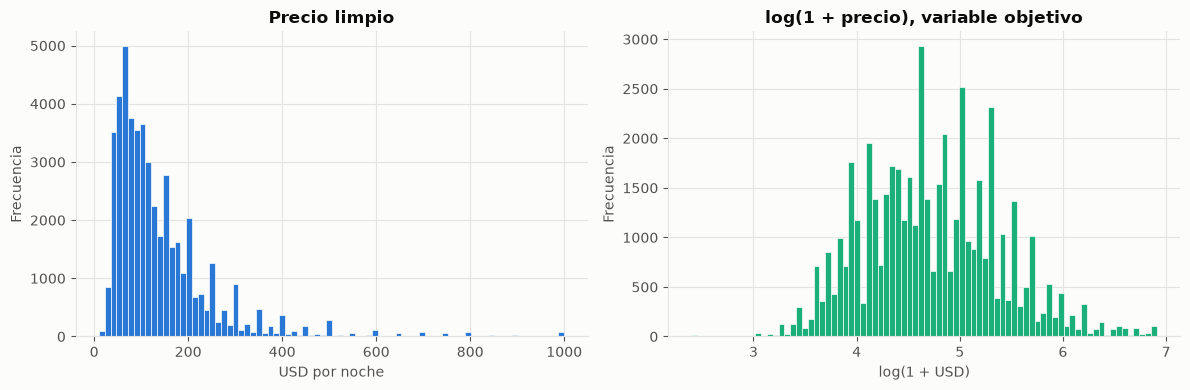

Asimetría precio: 2.94 | Asimetría log: 0.33


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean_df["price"], bins=80, color=train.COLORS["Ridge"], edgecolor=train.SURFACE, linewidth=0.5)
axes[0].set(title="Precio limpio", xlabel="USD por noche", ylabel="Frecuencia")
axes[1].hist(np.log1p(clean_df["price"]), bins=80, color=train.COLORS["MLP"], edgecolor=train.SURFACE, linewidth=0.5)
axes[1].set(title="log(1 + precio), variable objetivo", xlabel="log(1 + USD)", ylabel="Frecuencia")
fig.tight_layout()
fig.savefig(EVIDENCE / "eda_precio.png")
plt.show()
print(f"Asimetría precio: {clean_df['price'].skew():.2f} | Asimetría log: {np.log1p(clean_df['price']).skew():.2f}")

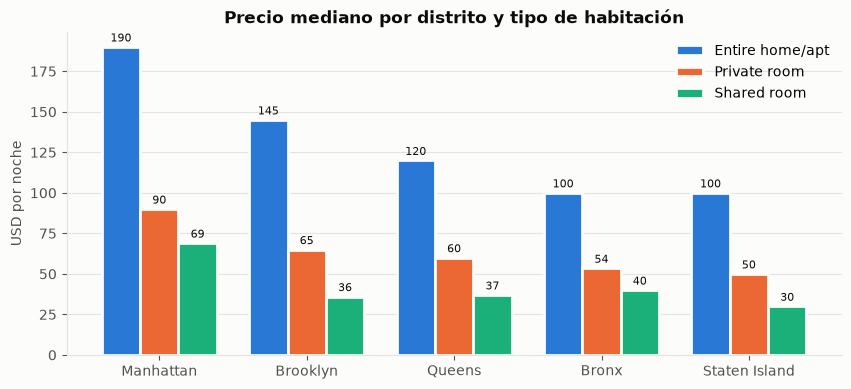

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Manhattan,190.000,90.000,69.000
Brooklyn,145.000,65.000,36.000
Queens,120.000,60.000,37.000
Bronx,100.000,53.500,40.000
Staten Island,100.000,50.000,30.000


In [12]:
median = clean_df.pivot_table(index="neighbourhood_group", columns="room_type", values="price", aggfunc="median")
median = median.loc[median.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 4.2))
width = 0.26
x = np.arange(len(median))
for i, (room, color) in enumerate(zip(median.columns, train.COLORS.values())):
    bars = ax.bar(x + (i - 1) * width, median[room], width, label=room, color=color, edgecolor=train.SURFACE, linewidth=2)
    ax.bar_label(bars, fmt="%.0f", padding=2, color=train.INK, fontsize=8)
ax.set(xticks=x, xticklabels=median.index, title="Precio mediano por distrito y tipo de habitación", ylabel="USD por noche")
ax.grid(axis="x", visible=False)
ax.legend(title=None)
fig.savefig(EVIDENCE / "eda_distrito_tipo.png")
plt.show()
median

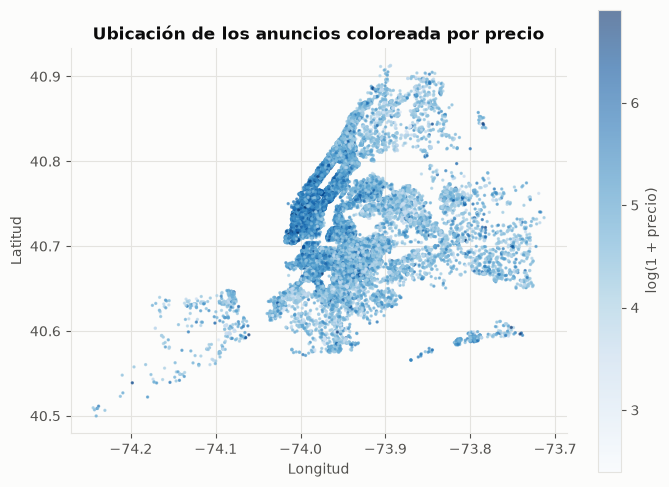

In [13]:
fig, ax = plt.subplots(figsize=(8, 7.5))
points = ax.scatter(clean_df["longitude"], clean_df["latitude"], c=np.log1p(clean_df["price"]), cmap="Blues", s=2, alpha=0.6)
fig.colorbar(points, ax=ax, label="log(1 + precio)", shrink=0.8)
ax.set(title="Ubicación de los anuncios coloreada por precio", xlabel="Longitud", ylabel="Latitud")
ax.set_aspect("equal")
fig.savefig(EVIDENCE / "eda_mapa.png")
plt.show()

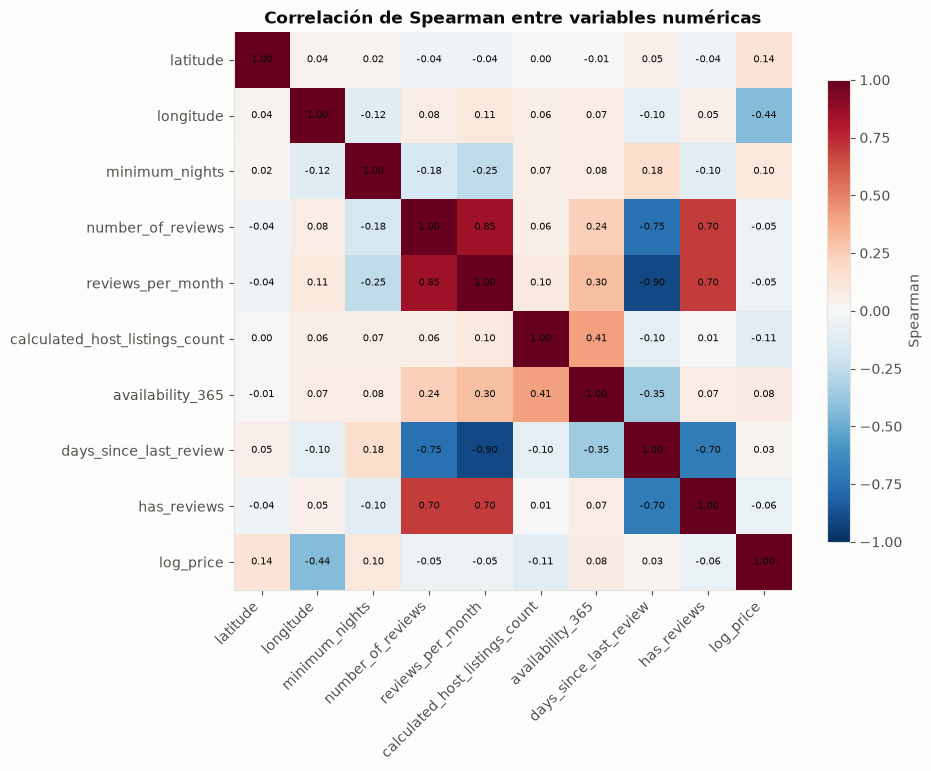

longitude                        -0.436
calculated_host_listings_count   -0.106
has_reviews                      -0.063
reviews_per_month                -0.054
number_of_reviews                -0.049
days_since_last_review            0.029
availability_365                  0.083
minimum_nights                    0.103
latitude                          0.136
Name: log_price, dtype: float64

In [14]:
numeric = clean_df[prep.NUMERIC + ["price"]].copy()
numeric["log_price"] = np.log1p(numeric.pop("price"))
corr = numeric.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=train.INK)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman")
ax.set_title("Correlación de Spearman entre variables numéricas")
fig.savefig(EVIDENCE / "eda_correlacion.png")
plt.show()
corr["log_price"].drop("log_price").sort_values()

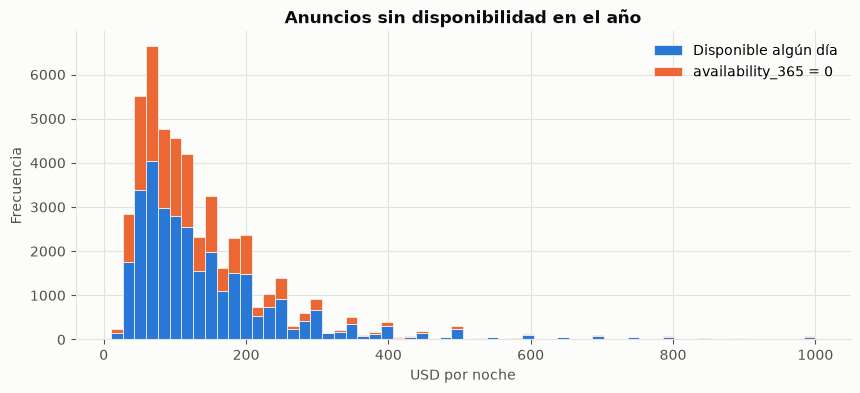

Anuncios con availability_365 = 0: 17,463 (35.9%)


In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
inactive = clean_df["availability_365"].eq(0)
ax.hist([clean_df.loc[~inactive, "price"], clean_df.loc[inactive, "price"]], bins=60, stacked=True, color=[train.COLORS["Ridge"], train.COLORS["XGBoost"]], edgecolor=train.SURFACE, linewidth=0.5, label=["Disponible algún día", "availability_365 = 0"])
ax.set(title="Anuncios sin disponibilidad en el año", xlabel="USD por noche", ylabel="Frecuencia")
ax.legend()
fig.savefig(EVIDENCE / "eda_disponibilidad.png")
plt.show()
print(f"Anuncios con availability_365 = 0: {inactive.sum():,} ({inactive.mean():.1%})")

## 5. Entrenamiento, ajuste y registro en MLflow

In [16]:
for name, spec in train.model_specs().items():
    combos = int(np.prod([len(v) for v in spec["grid"].values()]))
    print(f"{name}: {train.short_params(spec['grid'])} -> {combos} combinaciones x {train.FOLDS} folds = {combos * train.FOLDS} ajustes")

Ridge: {'alpha': [0.01, 0.1, 1, 10, 100]} -> 5 combinaciones x 10 folds = 50 ajustes
XGBoost: {'n_estimators': [300, 600, 1000], 'max_depth': [4, 6, 8, 10], 'learning_rate': [0.05, 0.1], 'subsample': [0.8, 1.0]} -> 48 combinaciones x 10 folds = 480 ajustes
MLP: {'hidden': [64, 128, 256], 'lr': [0.001, 0.003]} -> 6 combinaciones x 10 folds = 60 ajustes


In [17]:
output = train.run()

Dispositivo para MLP: mps
Entrenamiento: 38915 filas | Prueba: 9729 filas | Folds: 10


Ridge: mejores hiperparámetros {'alpha': 0.01}
Ridge: RMSE CV 94.72 +/- 3.64 | test MAE 49.16 RMSE 92.79 R2 0.364


XGBoost: mejores hiperparámetros {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 600, 'subsample': 0.8}
XGBoost: RMSE CV 86.53 +/- 3.62 | test MAE 44.36 RMSE 85.09 R2 0.465


MLP: mejores hiperparámetros {'hidden': 256, 'lr': 0.003}
MLP: RMSE CV 91.63 +/- 3.32 | test MAE 48.54 RMSE 88.52 R2 0.422


Modelo registrado: airbnb-nyc-price v1 (XGBoost) con alias champion
Friedman: chi2 20.000, p 4.54e-05
     comparacion  diferencia_media_rmse      t  p_t_pareada  w  p_wilcoxon
Ridge vs XGBoost                  8.187  21.39    5.014e-09  0    0.001953
    Ridge vs MLP                  3.085  6.345    0.0001337  0    0.001953
  XGBoost vs MLP                 -5.102 -8.779    1.046e-05  0    0.001953


Successfully registered model 'airbnb-nyc-price'.
Created version '1' of model 'airbnb-nyc-price'.


## 6. Resultados y comparación

In [18]:
output["summary"].drop(columns="run_id")

,modelo,mejores_hiperparametros,cv_rmse_media,cv_rmse_std,cv_r2_media,test_mae,test_rmse,test_r2
0,Ridge,{'alpha': 0.01},94.719,3.637,0.342,49.160,92.793,0.364
1,XGBoost,"{'learning_rate': 0.05, 'max_depth': 8, 'n_est...",86.532,3.617,0.451,44.364,85.089,0.465
2,MLP,"{'hidden': 256, 'lr': 0.003}",91.634,3.320,0.384,48.541,88.520,0.422


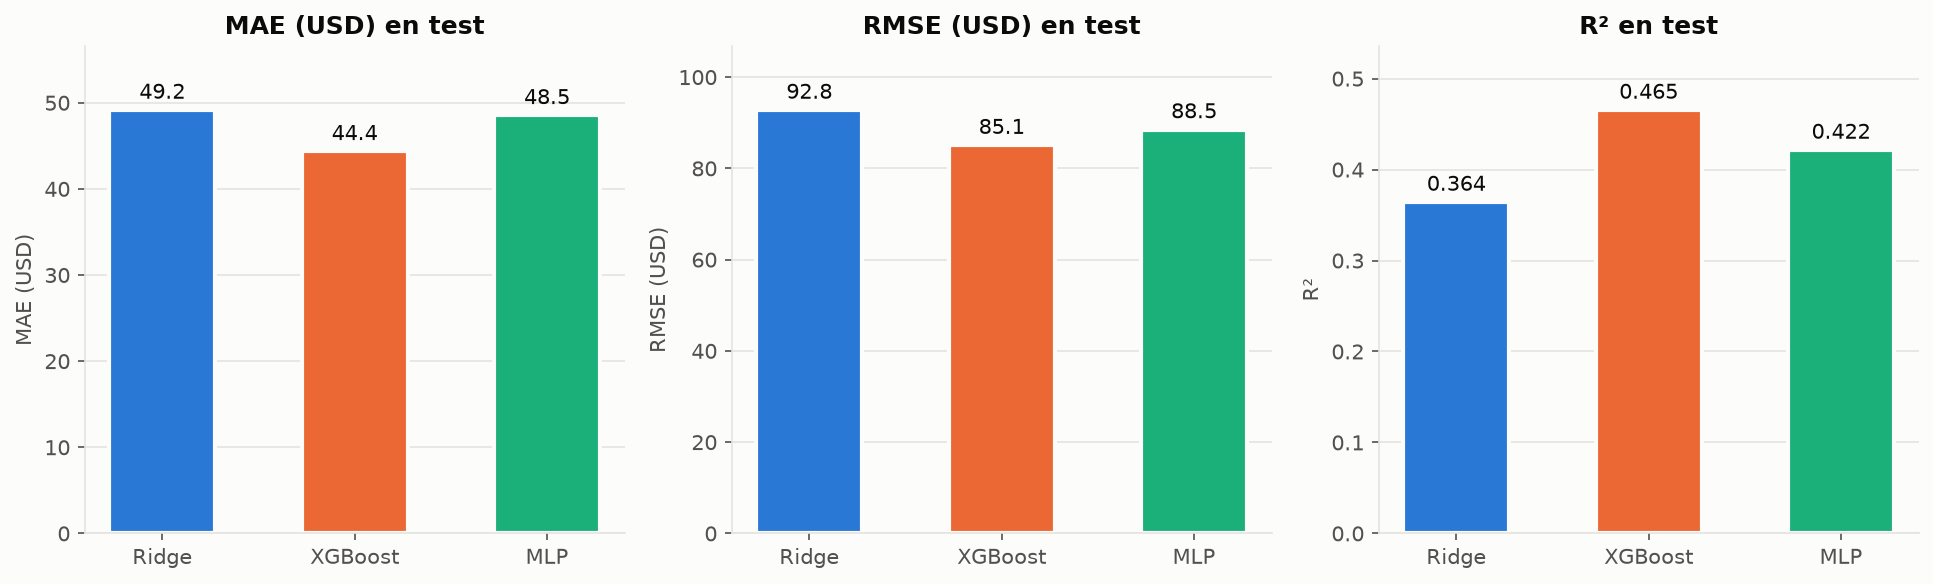

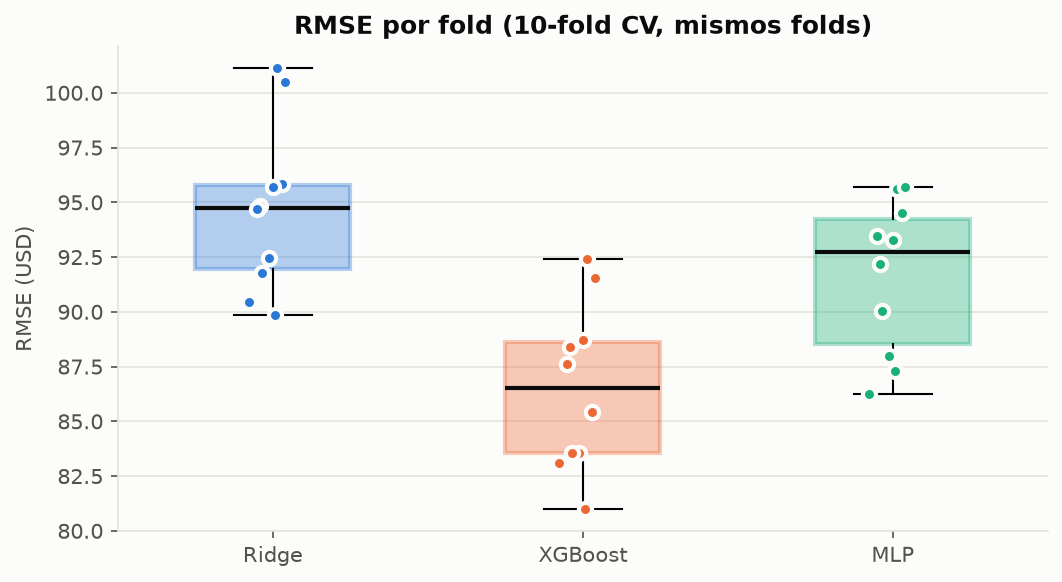

In [19]:
display(Image(EVIDENCE / "comparacion_metricas.png"))
display(Image(EVIDENCE / "rmse_por_fold.png"))

In [20]:
output["folds"].describe().T

,count,mean,std,min,25%,50%,75%,max
Ridge,10.000,94.719,3.834,89.843,91.960,94.762,95.784,101.117
XGBoost,10.000,86.532,3.812,80.982,83.540,86.536,88.626,92.433
MLP,10.000,91.634,3.499,86.270,88.511,92.731,94.240,95.710


In [21]:
friedman = output["friedman"]
print(f"Friedman: chi2 = {friedman.statistic:.3f}, p = {friedman.pvalue:.4g}")
output["tests"].style.format({"p_t_pareada": "{:.2e}", "p_wilcoxon": "{:.4f}"}, precision=3).hide(axis="index")

Friedman: chi2 = 20.000, p = 4.54e-05


comparacion,diferencia_media_rmse,t,p_t_pareada,w,p_wilcoxon
Ridge vs XGBoost,8.187,21.391,5.01e-09,0.000,0.0020
Ridge vs MLP,3.085,6.345,1.34e-04,0.000,0.0020
XGBoost vs MLP,-5.102,-8.779,1.05e-05,0.000,0.0020


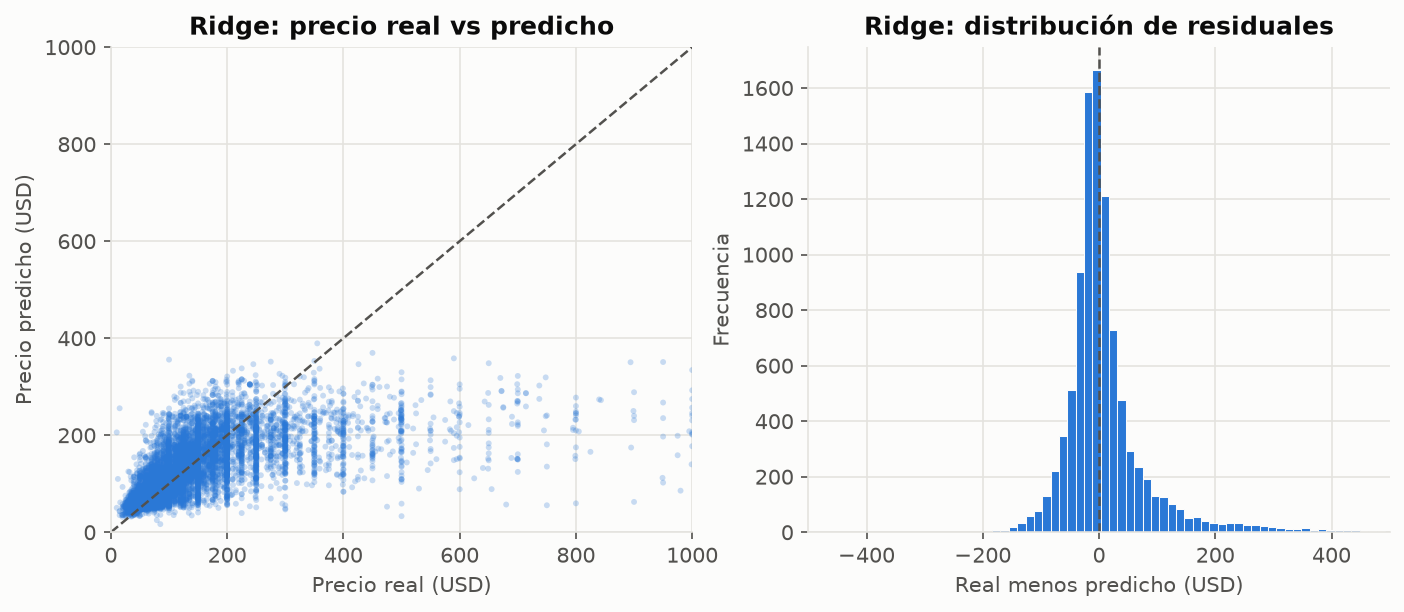

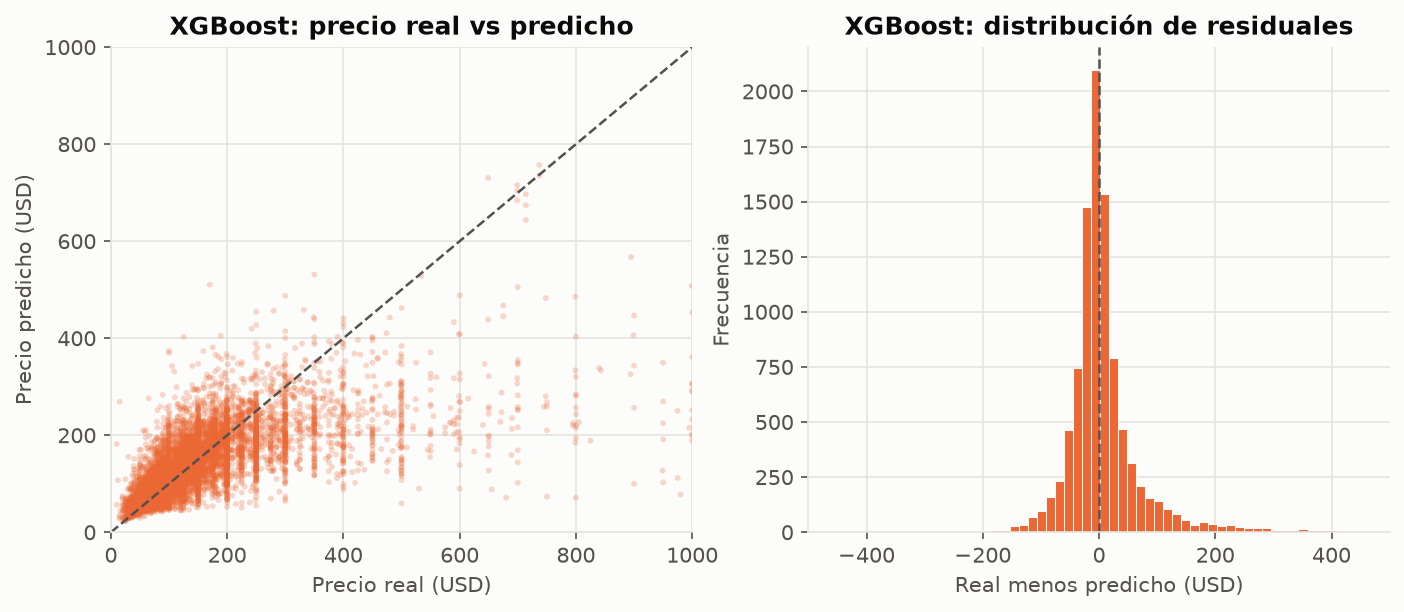

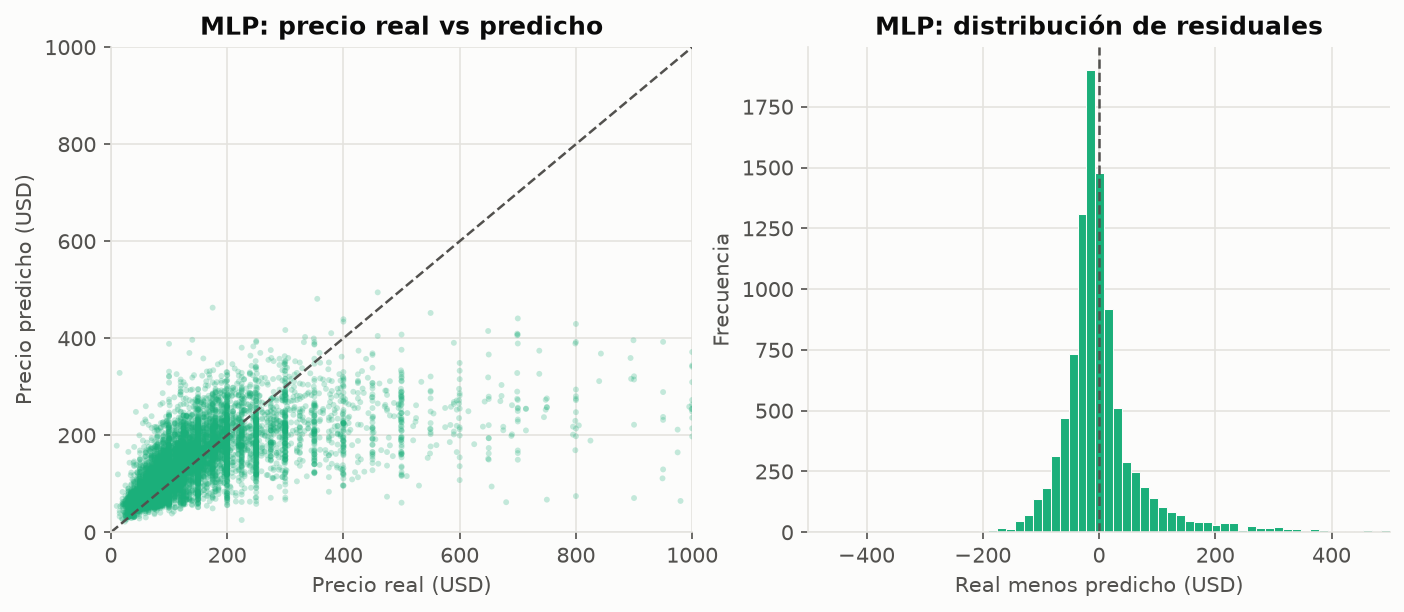

In [22]:
for name in ["ridge", "xgboost", "mlp"]:
    display(Image(EVIDENCE / f"pred_{name}.png"))

## 7. Evidencia en MLflow

In [23]:
runs = train.mlflow.search_runs(experiment_names=[train.EXPERIMENT])
columns = ["tags.mlflow.runName", "tags.stage", "metrics.cv_rmse_mean", "metrics.test_rmse", "metrics.test_r2"]
print(f"Runs registrados: {len(runs)}")
runs[columns].sort_values("tags.stage").head(12)

Runs registrados: 63


,tags.mlflow.runName,tags.stage,metrics.cv_rmse_mean,metrics.test_rmse,metrics.test_r2
0,Comparacion,comparison,NaN,NaN,NaN
1,MLP-05,grid_candidate,91.634,NaN,NaN
2,MLP-04,grid_candidate,92.775,NaN,NaN
3,MLP-03,grid_candidate,92.869,NaN,NaN
4,MLP-02,grid_candidate,92.557,NaN,NaN
5,MLP-01,grid_candidate,92.767,NaN,NaN
6,MLP-00,grid_candidate,93.903,NaN,NaN
8,XGBoost-47,grid_candidate,88.483,NaN,NaN
9,XGBoost-46,grid_candidate,88.631,NaN,NaN
10,XGBoost-45,grid_candidate,87.928,NaN,NaN


In [24]:
client = train.MlflowClient()
champion = client.get_model_version_by_alias(train.REGISTERED_MODEL, "champion")
print(f"Modelo registrado: {train.REGISTERED_MODEL} v{champion.version} ({champion.description})")
loaded = train.mlflow.pyfunc.load_model(f"models:/{train.REGISTERED_MODEL}@champion")
sample = clean_df.sample(5, random_state=train.SEED)
pd.DataFrame({"precio_real": sample["price"], "precio_predicho": np.expm1(loaded.predict(sample[prep.CATEGORICAL + prep.NUMERIC])).round(0)})

Modelo registrado: airbnb-nyc-price v1 (XGBoost con RMSE test 85.09 USD)


,precio_real,precio_predicho
1941,99,154.000
40004,70,88.000
15107,268,217.000
25858,47,61.000
29186,250,120.000
